# 02 — Data Cleaning and Quarterly Aggregation

## What this notebook does
1. **Clean raw data** — apply the import decisions documented in notebook 01 and construct consistent series for GPR, energy prices, HICP, IPI, GDP, and CLIFS
2. **Construct quarterly series** — perform the required source-specific treatments, including seasonal adjustment of monthly HICP, and aggregate monthly variables to quarterly frequency
3. **Explore the data** — provide a brief descriptive analysis and visual inspection of each cleaned quarterly variable
4. **Compare GDP and IPI** — assess both measures of economic activity and document the choice of IPI as the baseline activity variable
5. **Build the clean quarterly panel** — align all series with the master quarterly skeleton, validate the resulting dataset, and export it for the subsequent econometric transformations

## Final empirical scope
Baseline system: `[GPR_origin, Brent, Gas_TTF, HICP, IPI, CLIFS]`

HICP is seasonally adjusted at monthly frequency before quarterly aggregation. The remaining source-specific cleaning and aggregation decisions follow those documented in notebook 01.

This notebook keeps the cleaned quarterly variables in levels. The transformations required for BVAR estimation are applied in the subsequent notebook.

## Block A — Setup

In [3]:
from pathlib import Path
import sys

# Support both Google Colab and local execution
try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/drive/MyDrive/TFM_GitHub")
except ImportError:
    PROJECT_ROOT = Path.cwd().resolve()
    if PROJECT_ROOT.name == "notebooks":
        PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "src" / "paths.py").exists():
    raise FileNotFoundError(
        f"Could not find src/paths.py under: {PROJECT_ROOT}"
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.paths import *

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print(f"pandas {pd.__version__}")
print(f"numpy  {np.__version__}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
pandas 2.2.3
numpy  2.1.3


In [4]:
# Load the master quarterly skeleton created in notebook 01

if not SKELETON_PATH.exists():
    raise FileNotFoundError(
        f"Skeleton not found at: {SKELETON_PATH}\n"
        "Run notebook 01 first."
    )

skeleton = pd.read_excel(SKELETON_PATH)
skeleton["quarter"] = skeleton["quarter"].astype(str)

print(
    f"Skeleton loaded: {len(skeleton)} quarters "
    f"({skeleton['quarter'].iloc[0]} – {skeleton['quarter'].iloc[-1]})"
)
skeleton.head()

Skeleton loaded: 116 quarters (1997Q1 – 2025Q4)


,quarter,year,q
0,1997Q1,1997,1
1,1997Q2,1997,2
2,1997Q3,1997,3
3,1997Q4,1997,4
4,1998Q1,1998,1


In [5]:
def assign_quarter(date_series):
    """Convert quarterly or monthly/daily dates to 'YYYYQq' labels."""
    values = date_series.astype(str)

    if values.str.match(r"\d{4}-Q\d").any():
        return values.str.replace("-Q", "Q", regex=False)

    periods = pd.PeriodIndex(pd.to_datetime(date_series), freq="Q")
    return periods.astype(str)


def restrict_to_skeleton(df, quarter_col="quarter"):
    """Keep observations inside the master quarterly skeleton."""
    valid_quarters = set(skeleton["quarter"])
    return df[df[quarter_col].isin(valid_quarters)].copy()


def plot_country_series(df, value_col, title, ylabel=None):
    """Plot one quarterly series for each recipient economy."""
    pivot = df.pivot(index="quarter", columns="country", values=value_col)
    ax = pivot.plot(figsize=(11, 5))
    ax.set_title(title)
    ax.set_xlabel("Quarter")
    ax.set_ylabel(ylabel or value_col)
    ax.tick_params(axis="x", labelrotation=45)
    plt.tight_layout()
    plt.show()

## Block B — Source-specific cleaning, quarterly aggregation and descriptive analysis

Each subsection follows the same logic:

**raw data → cleaning → source-specific treatment → quarterly series → brief EDA**

No BVAR transformations are applied here.

### B1. Bilateral GPR

The bilateral GPR database is already quarterly. For each recipient economy, retain the four geographical origins used in the analysis: **Russia, China, Middle East and Western Bloc**.

In [6]:
GPR_ORIGIN_COLS = {
    "Russia": "GPR_Russia",
    "China": "GPR_China",
    "Middle East": "GPR_MENA",
    "Western Bloc": "GPR_Western",
}

gpr_frames = []

for country in TARGET_COUNTRIES:
    df = pd.read_excel(
        RAW_FILES["gpr"],
        sheet_name=country,
        header=0,
    )

    cols_to_keep = ["Date"] + list(GPR_ORIGIN_COLS)
    missing = [col for col in cols_to_keep if col not in df.columns]
    if missing:
        raise ValueError(f"GPR sheet {country} — missing columns: {missing}")

    df = df[cols_to_keep].copy()
    df["quarter"] = assign_quarter(df["Date"])
    df = df.drop(columns="Date").rename(columns=GPR_ORIGIN_COLS)
    df["country"] = country

    gpr_frames.append(df)

gpr = pd.concat(gpr_frames, ignore_index=True)
gpr = restrict_to_skeleton(gpr)

print(f"GPR: {len(gpr)} country-quarter observations")
print(f"Range: {gpr['quarter'].min()} – {gpr['quarter'].max()}")
display(gpr.head())

GPR: 464 country-quarter observations
Range: 1997Q1 – 2025Q4


,GPR_Russia,GPR_China,GPR_MENA,GPR_Western,quarter,country
0,9.474874,0.000000,38.046743,24.595479,1997Q1,Germany
1,22.084295,33.970353,45.825273,44.950218,1997Q2,Germany
2,16.060424,18.116527,56.571306,52.981891,1997Q3,Germany
3,27.573389,21.533135,91.446570,62.973780,1997Q4,Germany
4,15.280629,8.618450,88.003144,65.697519,1998Q1,Germany


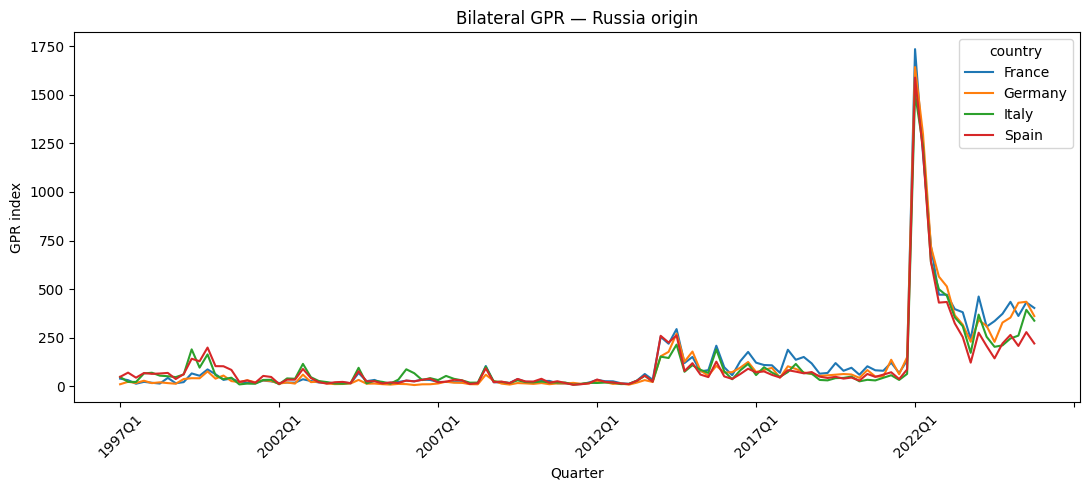

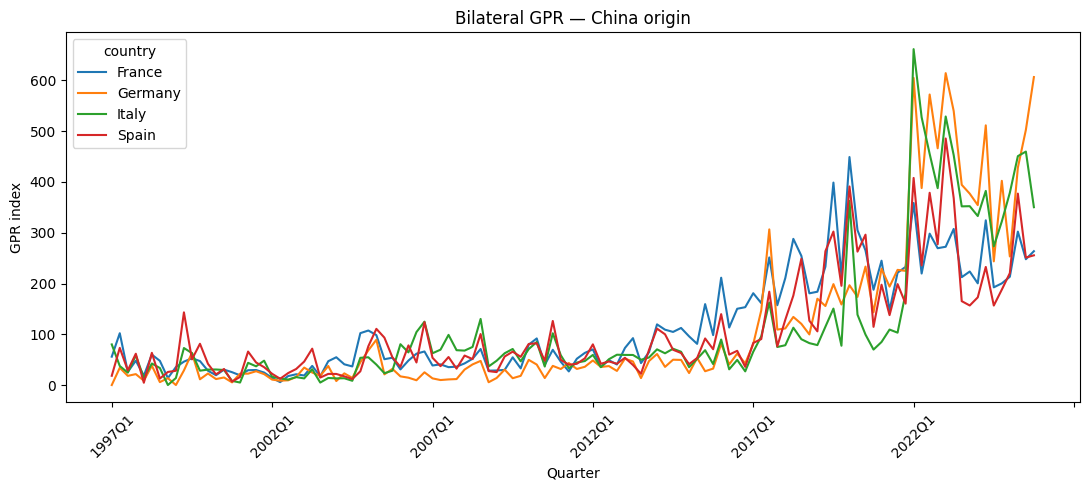

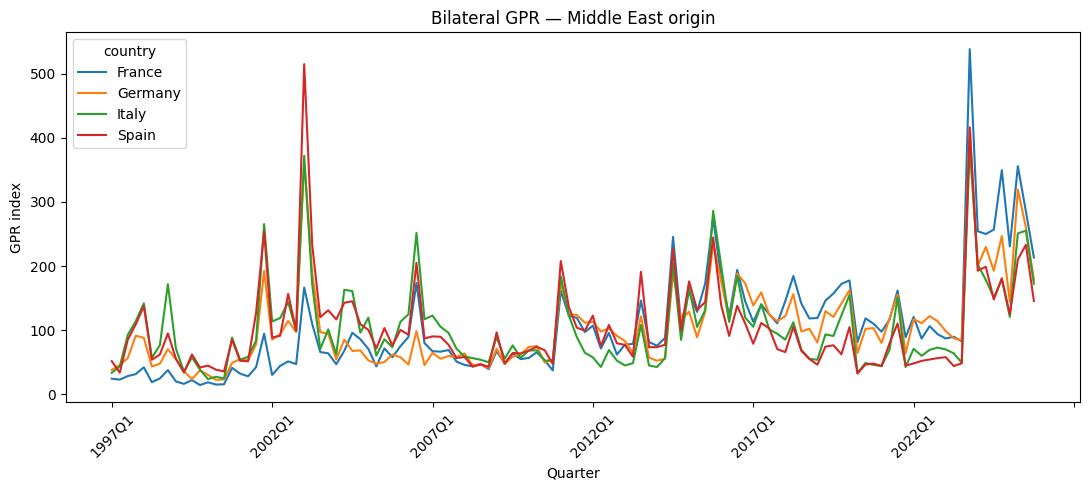

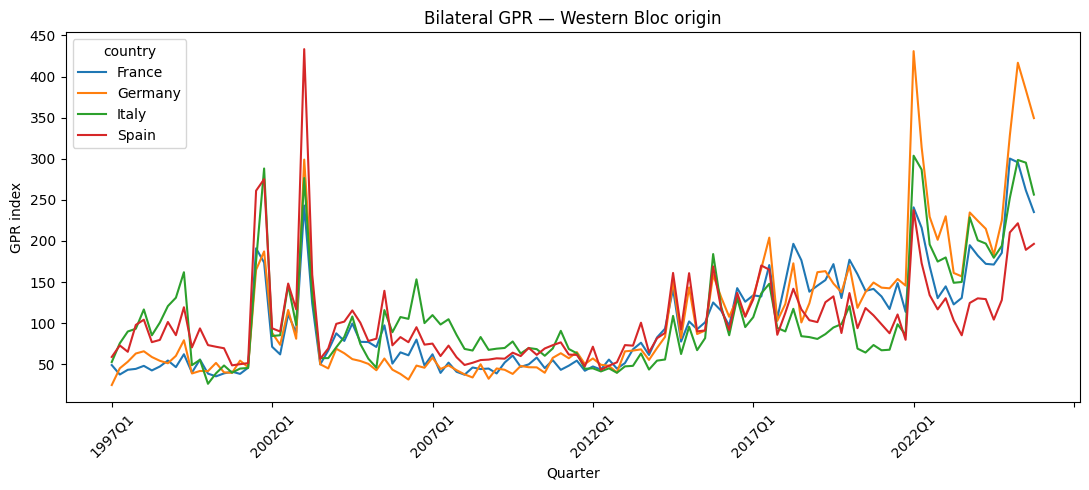

GPR_Russia                         GPR_China                        \
              mean     std    min      max      mean     std   min     max   
country                                                                      
France      124.77  225.24  10.70  1735.96    116.40  100.21  5.72  449.16   
Germany     110.15  223.71   5.35  1643.60    111.99  155.68  0.00  614.42   
Italy       107.20  202.10   6.98  1508.10    110.69  135.20  0.00  661.73   
Spain       104.33  200.38   6.60  1589.08    106.07  100.44  4.53  485.67   

        GPR_MENA                       GPR_Western                        
            mean    std    min     max        mean    std    min     max  
country                                                                   
France    104.70  81.08  14.47  537.99      100.58  61.67  35.19  300.22  
Germany   104.33  66.93  22.52  415.24      109.29  85.28  24.60  430.94  
Italy     103.44  66.74  23.73  384.91      106.06  63.68  26.12  303.68  
Spain     103.03  70.89  32.47  514.61      104.08  54.68  43.15  433.39

In [7]:
# Brief EDA: GPR series by origin and recipient economy

for variable, label in {
    "GPR_Russia": "Russia",
    "GPR_China": "China",
    "GPR_MENA": "Middle East",
    "GPR_Western": "Western Bloc",
}.items():
    plot_country_series(
        gpr,
        variable,
        title=f"Bilateral GPR — {label} origin",
        ylabel="GPR index",
    )

display(
    gpr.groupby("country")[list(GPR_ORIGIN_COLS.values())]
       .agg(["mean", "std", "min", "max"])
       .round(2)
)

### B2. Energy prices

Brent crude oil and European natural gas prices are taken from the World Bank Pink Sheet in their original **USD denomination**. Monthly observations are aggregated to quarterly frequency using the quarterly mean.

In [8]:
def parse_worldbank_date(text):
    import re

    match = re.match(r"(\d{4})M(\d{2})", str(text))
    if match:
        year, month = match.groups()
        return pd.Timestamp(year=int(year), month=int(month), day=1)

    return pd.NaT


energy_raw = pd.read_excel(
    RAW_FILES["energy"],
    sheet_name="Monthly Prices",
    header=4,
)

brent_col = "Crude oil, Brent"
gas_col = "Natural gas, Europe"

for col in [brent_col, gas_col]:
    if col not in energy_raw.columns:
        raise ValueError(
            f"Column '{col}' not found. "
            f"Available columns: {energy_raw.columns.tolist()}"
        )

date_col = energy_raw.columns[0]

energy = energy_raw[[date_col, brent_col, gas_col]].copy()
energy.columns = ["date", "brent_usd", "gas_usd"]

energy["date"] = energy["date"].apply(parse_worldbank_date)
energy["brent_usd"] = pd.to_numeric(energy["brent_usd"], errors="coerce")
energy["gas_usd"] = pd.to_numeric(energy["gas_usd"], errors="coerce")

energy = energy.dropna(subset=["date"])
energy["quarter"] = assign_quarter(energy["date"])

energy_q = (
    energy.groupby("quarter", as_index=False)[["brent_usd", "gas_usd"]]
          .mean()
)

energy_q = restrict_to_skeleton(energy_q)

print(f"Energy: {len(energy_q)} quarterly observations")
print(f"Range: {energy_q['quarter'].min()} – {energy_q['quarter'].max()}")
display(energy_q.head())

Energy: 116 quarterly observations
Range: 1997Q1 – 2025Q4


,quarter,brent_usd,gas_usd
148,1997Q1,21.170000,2.870000
149,1997Q2,18.053333,2.756667
150,1997Q3,18.520000,2.680000
151,1997Q4,18.616667,2.646667
152,1998Q1,14.076667,2.630000


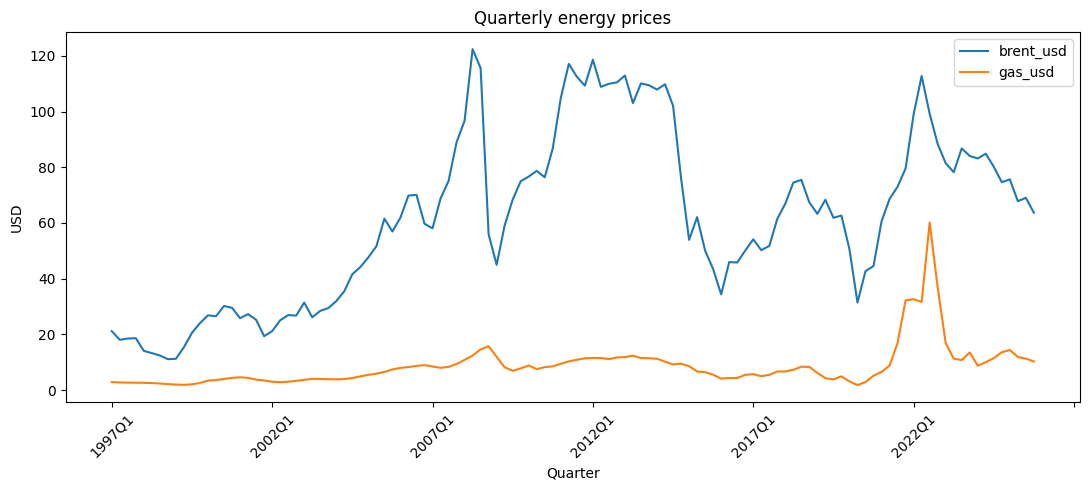

,brent_usd,gas_usd
count,116.00,116.00
mean,61.64,8.60
std,30.60,7.73
min,11.09,1.82
max,122.39,60.16


In [9]:
# Brief EDA: quarterly Brent and European natural gas prices

ax = energy_q.set_index("quarter")[["brent_usd", "gas_usd"]].plot(
    figsize=(11, 5)
)
ax.set_title("Quarterly energy prices")
ax.set_xlabel("Quarter")
ax.set_ylabel("USD")
ax.tick_params(axis="x", labelrotation=45)
plt.tight_layout()
plt.show()

display(
    energy_q[["brent_usd", "gas_usd"]]
    .describe()
    .loc[["count", "mean", "std", "min", "max"]]
    .round(2)
)

### B3. HICP — seasonal adjustment before quarterly aggregation

Eurostat's national HICP series are not seasonally adjusted. The adjustment is therefore applied to the **monthly HICP series before quarterly aggregation**.

The final TFM specification uses **TRAMO-SEATS through JDemetra+/RJDemetra**. The adjusted monthly series are then aggregated using the quarterly mean.

The notebook also keeps the raw monthly series temporarily so that the effect of seasonal adjustment can be inspected visually.

In [10]:
# Colab setup for RJDemetra/JDemetra+
# Run once per fresh Colab runtime.

!apt-get update -qq
!apt-get install -y -qq r-base-core default-jdk-headless
!R CMD javareconf
!R -e 'if (!requireNamespace("RJDemetra", quietly=TRUE)) install.packages("RJDemetra", repos="https://cloud.r-project.org")'
!pip install rpy2 --quiet

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package default-jre-headless.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../default-jre-headless_2%3a1.21-75+exp1_amd64.deb ...
Unpacking default-jre-headless (2:1.21-75+exp1) ...
Selecting previously unselected package default-jdk-headless.
Preparing to unpack .../default-jdk-headless_2%3a1.21-75+exp1_amd64.deb ...
Unpacking default-jdk-headless (2:1.21-75+exp1) ...
Setting up default-jre-headless (2:1.21-75+exp1) ...
Setting up default-jdk-headless (2:1.21-75+exp1) ...
Java interpreter : /usr/lib/jvm/default-java/bin/java
[0.023s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.023s][warning][os,container] 

In [11]:
import ctypes
import os
import subprocess

java_home = subprocess.run(
    ["bash", "-c", "readlink -f $(which java) | sed 's:/bin/java::'"],
    capture_output=True,
    text=True,
).stdout.strip()

libjvm_path = subprocess.run(
    ["bash", "-c", f"find {java_home} -name 'libjvm.so' | head -n 1"],
    capture_output=True,
    text=True,
).stdout.strip()

if not libjvm_path:
    raise FileNotFoundError(
        "libjvm.so not found under JAVA_HOME — check the JDK installation."
    )

ctypes.CDLL(libjvm_path, mode=ctypes.RTLD_GLOBAL)
os.environ["JAVA_HOME"] = java_home
os.environ["LD_LIBRARY_PATH"] = (
    os.path.dirname(libjvm_path)
    + ":"
    + os.environ.get("LD_LIBRARY_PATH", "")
)

import rpy2.robjects as robjects


def decimal_year_to_date(decimal_years):
    years = np.floor(decimal_years).astype(int)
    months = np.round((decimal_years - years) * 12).astype(int) + 1
    return pd.to_datetime({"year": years, "month": months, "day": 1})


def seasonally_adjust_hicp(monthly_series):
    """Seasonally adjust a monthly HICP series using TRAMO-SEATS."""
    monthly_series = monthly_series.sort_index().dropna()

    robjects.globalenv["hicp_values"] = robjects.FloatVector(
        monthly_series.astype(float).values
    )
    robjects.globalenv["start_year"] = monthly_series.index[0].year
    robjects.globalenv["start_month"] = monthly_series.index[0].month

    robjects.r('''
        library(RJDemetra)
        ts_series <- ts(
            hicp_values,
            start=c(start_year, start_month),
            frequency=12
        )
        sa_result <- tramoseats(ts_series)
        sa_column <- sa_result$final$series[, "sa"]
        sa_dates <- time(sa_column)
    ''')

    values = np.array(robjects.r("as.numeric(sa_column)"))
    dates_decimal = np.array(robjects.r("as.numeric(sa_dates)"))
    dates = decimal_year_to_date(dates_decimal)

    return pd.Series(values, index=dates, name="hicp_sa")

In [12]:
hicp_raw = pd.read_excel(
    RAW_FILES["hicp"],
    sheet_name="Sheet 1",
    header=8,
    index_col=0,
)

hicp_countries = hicp_raw.loc[
    hicp_raw.index.isin(TARGET_COUNTRIES)
].copy()

missing_countries = [
    country
    for country in TARGET_COUNTRIES
    if country not in hicp_countries.index
]
if missing_countries:
    raise ValueError(f"HICP — missing countries: {missing_countries}")

raw_frames = []
adjusted_frames = []

for country in TARGET_COUNTRIES:
    monthly = hicp_countries.loc[country].replace(
        {":": np.nan, "…": np.nan}
    )
    monthly = pd.to_numeric(monthly, errors="coerce").dropna()
    monthly.index = pd.to_datetime(
        monthly.index.astype(str),
        format="%Y-%m",
    )
    monthly = monthly.sort_index()

    raw_country = monthly.rename("hicp_raw").reset_index()
    raw_country.columns = ["date", "hicp_raw"]
    raw_country["country"] = country
    raw_frames.append(raw_country)

    adjusted = seasonally_adjust_hicp(monthly)
    adjusted_country = adjusted.reset_index()
    adjusted_country.columns = ["date", "hicp"]
    adjusted_country["country"] = country
    adjusted_frames.append(adjusted_country)

    print(
        f"{country}: {len(monthly)} raw monthly observations; "
        f"{len(adjusted)} seasonally adjusted observations"
    )

hicp_monthly_raw = pd.concat(raw_frames, ignore_index=True)
hicp_monthly_sa = pd.concat(adjusted_frames, ignore_index=True)

hicp_monthly_sa["quarter"] = assign_quarter(hicp_monthly_sa["date"])

hicp_q = (
    hicp_monthly_sa
    .groupby(["quarter", "country"], as_index=False)["hicp"]
    .mean()
)

hicp_q = restrict_to_skeleton(hicp_q)

print(f"\nHICP quarterly panel: {len(hicp_q)} observations")
print(f"Range: {hicp_q['quarter'].min()} – {hicp_q['quarter'].max()}")
display(hicp_q.head())

/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/tmp/ipykernel_1395/2398471676.py:24: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  monthly = hicp_countries.loc[country].replace(


[0.001s]


ERROR: Could not write log
[0.006s] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Germany: 360 raw monthly observations; 360 seasonally adjusted observations


/tmp/ipykernel_1395/2398471676.py:24: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  monthly = hicp_countries.loc[country].replace(


France: 360 raw monthly observations; 360 seasonally adjusted observations


/tmp/ipykernel_1395/2398471676.py:24: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  monthly = hicp_countries.loc[country].replace(


Italy: 360 raw monthly observations; 360 seasonally adjusted observations


/tmp/ipykernel_1395/2398471676.py:24: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  monthly = hicp_countries.loc[country].replace(


Spain: 360 raw monthly observations; 360 seasonally adjusted observations

HICP quarterly panel: 464 observations
Range: 1997Q1 – 2025Q4


,quarter,country,hicp
16,1997Q1,France,75.680072
17,1997Q1,Germany,76.598778
18,1997Q1,Italy,69.388538
19,1997Q1,Spain,65.791649
20,1997Q2,France,75.632409


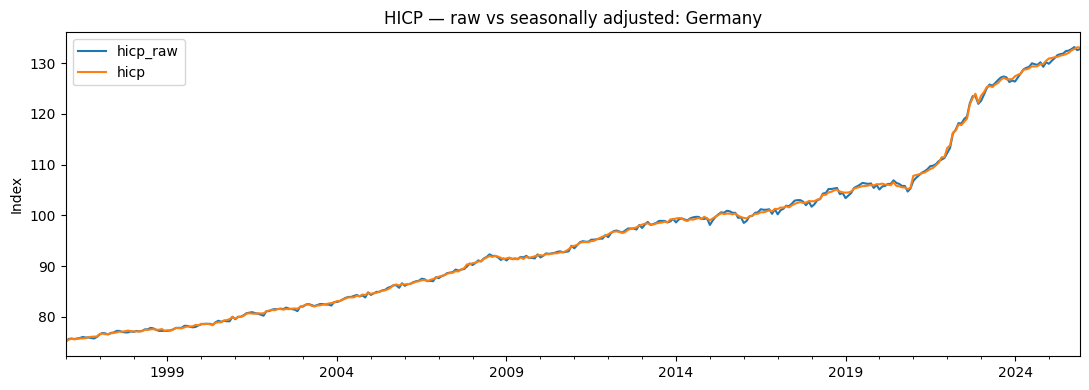

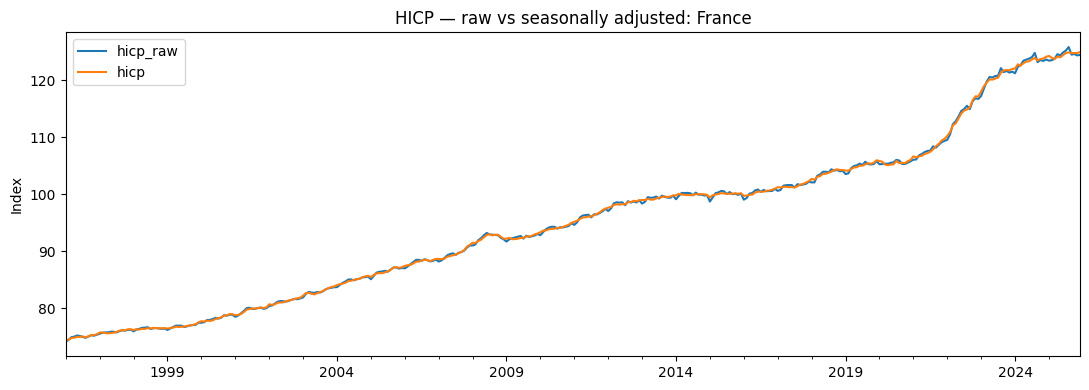

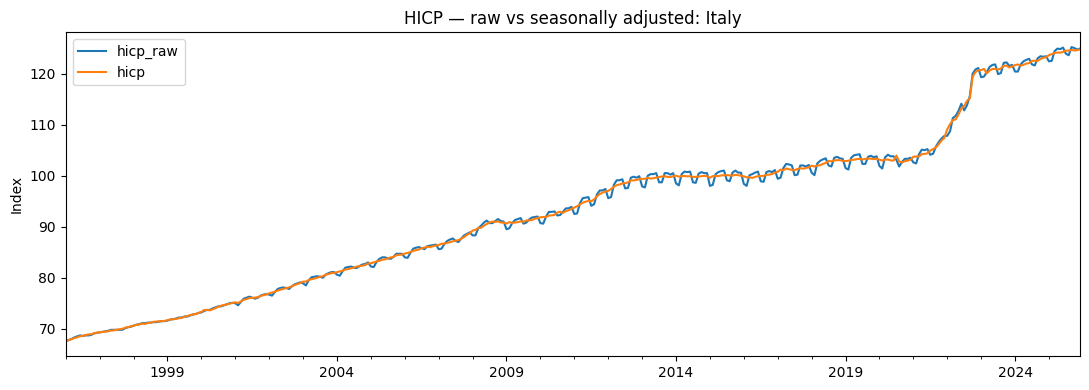

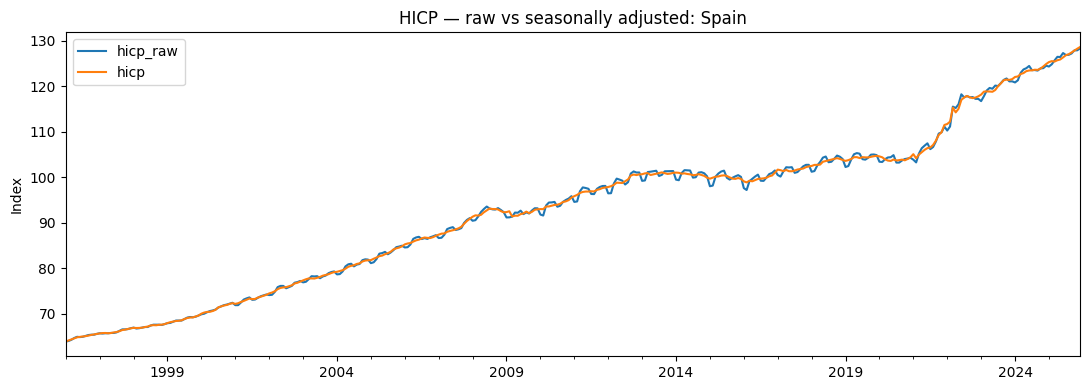

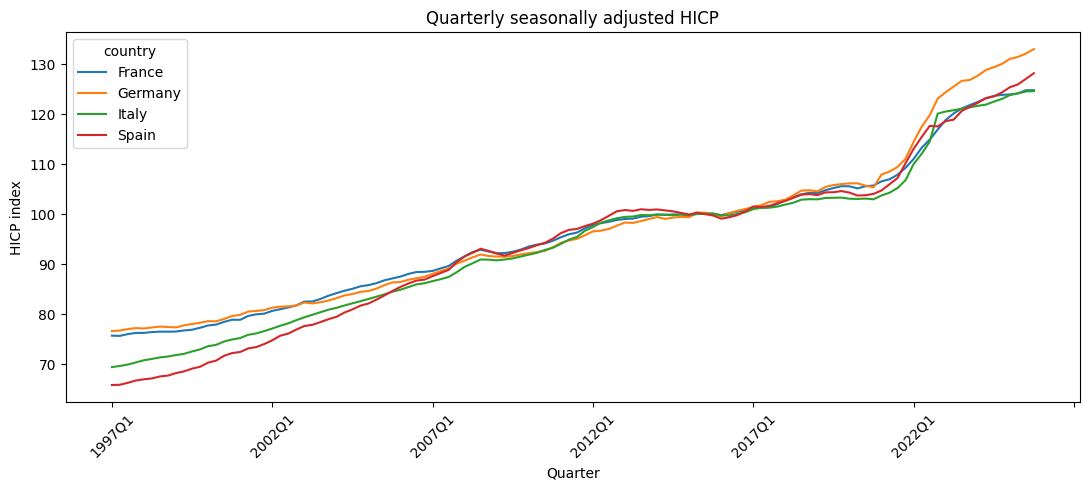

In [13]:
# Brief EDA: raw monthly HICP versus seasonally adjusted HICP

for country in TARGET_COUNTRIES:
    raw_country = (
        hicp_monthly_raw[hicp_monthly_raw["country"] == country]
        .set_index("date")["hicp_raw"]
    )
    sa_country = (
        hicp_monthly_sa[hicp_monthly_sa["country"] == country]
        .set_index("date")["hicp"]
    )

    comparison = pd.concat(
        [raw_country, sa_country],
        axis=1,
        join="inner",
    )

    ax = comparison.plot(figsize=(11, 4))
    ax.set_title(f"HICP — raw vs seasonally adjusted: {country}")
    ax.set_xlabel("")
    ax.set_ylabel("Index")
    plt.tight_layout()
    plt.show()

plot_country_series(
    hicp_q,
    "hicp",
    title="Quarterly seasonally adjusted HICP",
    ylabel="HICP index",
)

### B4. Industrial Production Index (IPI)

The Eurostat IPI file is monthly. Missing-value markers are converted to `NaN`, the data are reshaped to country-month format, and monthly observations are aggregated using the quarterly mean.

In [14]:
ipi_raw = pd.read_excel(
    RAW_FILES["ipi"],
    sheet_name="Sheet 1",
    header=10,
    index_col=0,
)

ipi_raw = ipi_raw.loc[
    ~ipi_raw.index.astype(str).str.contains("GEO", na=False)
]

ipi_countries = ipi_raw.loc[
    ipi_raw.index.isin(TARGET_COUNTRIES)
].copy()

missing_countries = [
    country
    for country in TARGET_COUNTRIES
    if country not in ipi_countries.index
]
if missing_countries:
    raise ValueError(f"IPI — missing countries: {missing_countries}")

ipi_long = (
    ipi_countries
    .reset_index()
    .rename(columns={ipi_countries.index.name or "index": "country"})
    .melt(id_vars="country", var_name="date", value_name="ipi")
)

ipi_long["ipi"] = ipi_long["ipi"].replace(
    {":": np.nan, "…": np.nan}
)
ipi_long["ipi"] = pd.to_numeric(ipi_long["ipi"], errors="coerce")
ipi_long = ipi_long.dropna(subset=["ipi"])

ipi_long["quarter"] = assign_quarter(ipi_long["date"])

ipi_q = (
    ipi_long
    .groupby(["quarter", "country"], as_index=False)["ipi"]
    .mean()
)

ipi_q = restrict_to_skeleton(ipi_q)

print(f"IPI: {len(ipi_q)} country-quarter observations")
print(f"Range: {ipi_q['quarter'].min()} – {ipi_q['quarter'].max()}")
display(ipi_q.head())

IPI: 464 country-quarter observations
Range: 1997Q1 – 2025Q4


/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/tmp/ipykernel_1395/1063324267.py:31: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ipi_long["ipi"] = ipi_long["ipi"].replace(


,quarter,country,ipi
100,1997Q1,France,95.500000
101,1997Q1,Germany,76.066667
102,1997Q1,Italy,111.933333
103,1997Q1,Spain,103.333333
104,1997Q2,France,98.500000


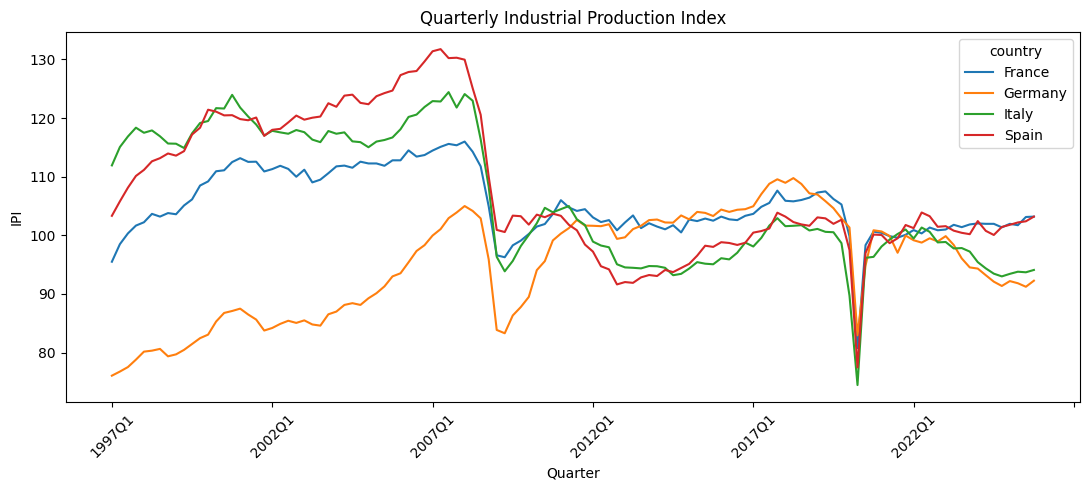

,count,mean,std,min,max
country,,,,,
France,116,105.25,5.60,80.77,116.00
Germany,116,94.82,8.96,76.07,109.77
Italy,116,106.07,11.01,74.47,124.43
Spain,116,107.98,11.67,77.47,131.77


In [15]:
plot_country_series(
    ipi_q,
    "ipi",
    title="Quarterly Industrial Production Index",
    ylabel="IPI",
)

display(
    ipi_q.groupby("country")["ipi"]
         .agg(["count", "mean", "std", "min", "max"])
         .round(2)
)

### B5. GDP

GDP is already quarterly in the source file. It is cleaned and reshaped but does not require temporal aggregation.

In [16]:
gdp_raw = pd.read_excel(
    RAW_FILES["gdp"],
    sheet_name="Sheet 1",
    header=9,
    index_col=0,
)

gdp_countries = gdp_raw.loc[
    gdp_raw.index.isin(TARGET_COUNTRIES)
].copy()

missing_countries = [
    country
    for country in TARGET_COUNTRIES
    if country not in gdp_countries.index
]
if missing_countries:
    raise ValueError(f"GDP — missing countries: {missing_countries}")

gdp_q = (
    gdp_countries
    .reset_index()
    .rename(columns={gdp_countries.index.name or "index": "country"})
    .melt(id_vars="country", var_name="date", value_name="gdp")
)

gdp_q["gdp"] = gdp_q["gdp"].replace(
    {":": np.nan, "…": np.nan}
)
gdp_q["gdp"] = pd.to_numeric(gdp_q["gdp"], errors="coerce")
gdp_q = gdp_q.dropna(subset=["gdp"])

gdp_q["quarter"] = assign_quarter(gdp_q["date"])
gdp_q = gdp_q[["quarter", "country", "gdp"]]
gdp_q = restrict_to_skeleton(gdp_q).reset_index(drop=True)

print(f"GDP: {len(gdp_q)} country-quarter observations")
print(f"Range: {gdp_q['quarter'].min()} – {gdp_q['quarter'].max()}")
display(gdp_q.head())

GDP: 464 country-quarter observations
Range: 1997Q1 – 2025Q4


/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/tmp/ipykernel_1395/465072561.py:27: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  gdp_q["gdp"] = gdp_q["gdp"].replace(


,quarter,country,gdp
0,1997Q1,Germany,77.772
1,1997Q1,Spain,69.662
2,1997Q1,France,73.303
3,1997Q1,Italy,91.891
4,1997Q2,Germany,78.637


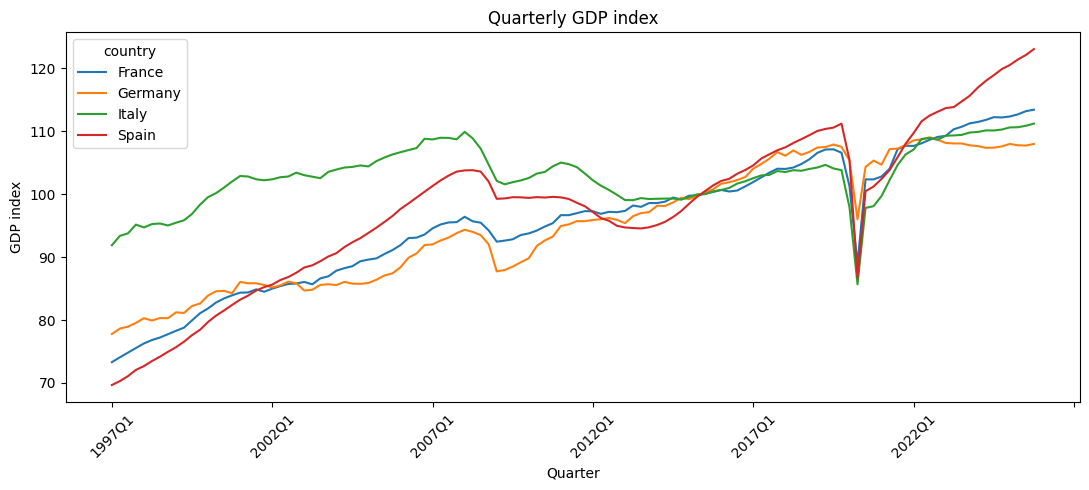

,count,mean,std,min,max
country,,,,,
France,116,95.66,10.30,73.30,113.44
Germany,116,95.20,9.64,77.77,109.04
Italy,116,102.99,4.67,85.68,111.22
Spain,116,97.82,12.50,69.66,123.06


In [17]:
plot_country_series(
    gdp_q,
    "gdp",
    title="Quarterly GDP index",
    ylabel="GDP index",
)

display(
    gdp_q.groupby("country")["gdp"]
         .agg(["count", "mean", "std", "min", "max"])
         .round(2)
)

### B6. CLIFS

The ECB Country-Level Index of Financial Stress is monthly. The four recipient economies are retained and monthly observations are aggregated using the quarterly mean.

In [18]:
clifs_raw = pd.read_excel(
    RAW_FILES["clifs"],
    sheet_name="DATA",
    header=14,
)

date_col = clifs_raw.columns[0]

country_cols = [
    col
    for col in clifs_raw.columns
    if any(country in str(col) for country in TARGET_COUNTRIES)
]

missing_countries = [
    country
    for country in TARGET_COUNTRIES
    if not any(country in str(col) for col in country_cols)
]
if missing_countries:
    raise ValueError(f"CLIFS — missing countries: {missing_countries}")

clifs = clifs_raw[[date_col] + country_cols].copy()
clifs.columns = ["date"] + [
    next(
        country
        for country in TARGET_COUNTRIES
        if country in str(col)
    )
    for col in country_cols
]

clifs = clifs.dropna(subset=["date"])

clifs_long = clifs.melt(
    id_vars="date",
    var_name="country",
    value_name="clifs",
)

clifs_long["clifs"] = pd.to_numeric(
    clifs_long["clifs"],
    errors="coerce",
)
clifs_long = clifs_long.dropna(subset=["clifs"])

clifs_long["quarter"] = assign_quarter(clifs_long["date"])

clifs_q = (
    clifs_long
    .groupby(["quarter", "country"], as_index=False)["clifs"]
    .mean()
)

clifs_q = restrict_to_skeleton(clifs_q)

print(f"CLIFS: {len(clifs_q)} country-quarter observations")
print(f"Range: {clifs_q['quarter'].min()} – {clifs_q['quarter'].max()}")
display(clifs_q.head())

CLIFS: 464 country-quarter observations
Range: 1997Q1 – 2025Q4


/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,quarter,country,clifs
432,1997Q1,France,0.114067
433,1997Q1,Germany,0.085600
434,1997Q1,Italy,0.082000
435,1997Q1,Spain,0.089667
436,1997Q2,France,0.134633


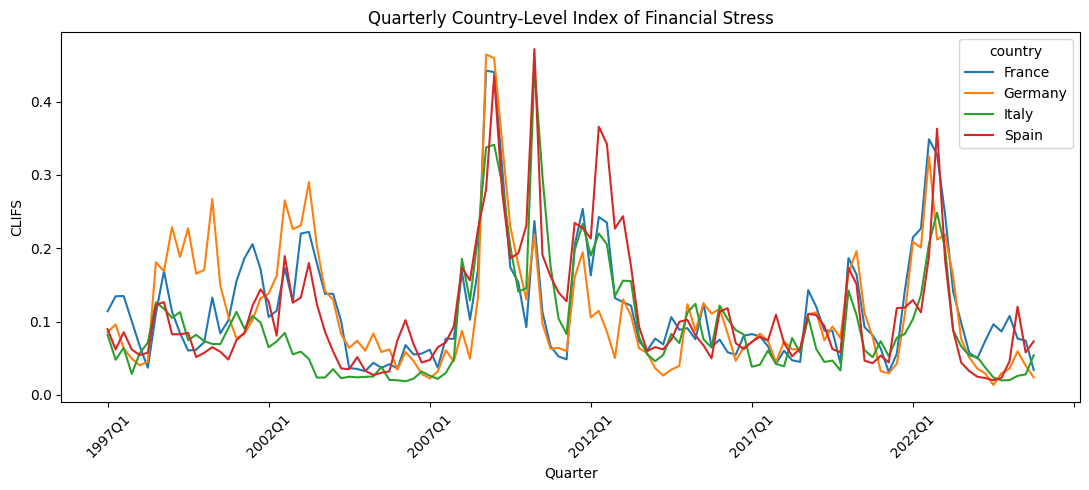

,count,mean,std,min,max
country,,,,,
France,116,0.118,0.079,0.031,0.442
Germany,116,0.114,0.085,0.014,0.464
Italy,116,0.095,0.077,0.019,0.447
Spain,116,0.114,0.085,0.020,0.472


In [19]:
plot_country_series(
    clifs_q,
    "clifs",
    title="Quarterly Country-Level Index of Financial Stress",
    ylabel="CLIFS",
)

display(
    clifs_q.groupby("country")["clifs"]
           .agg(["count", "mean", "std", "min", "max"])
           .round(3)
)

## Block C — GDP versus IPI: choice of activity indicator

IPI is the baseline measure of real activity, while GDP is retained as an alternative activity measure for the descriptive comparison reported here.

This block reproduces the descriptive comparison used to motivate that choice. The growth rates calculated here are **diagnostic only**: they are not yet the transformed variables exported for BVAR estimation.

In [20]:
activity = gdp_q.merge(
    ipi_q,
    on=["quarter", "country"],
    how="inner",
)

activity = activity.merge(
    energy_q[["quarter", "brent_usd"]],
    on="quarter",
    how="left",
)

activity = activity.sort_values(["country", "quarter"]).copy()

for variable in ["gdp", "ipi"]:
    activity[f"dlog_{variable}_diag"] = (
        activity.groupby("country")[variable]
        .transform(lambda x: np.log(x).diff())
    )

activity["dlog_brent_diag"] = np.log(
    activity["brent_usd"]
).diff()

# Brent is common to all countries. Recalculate within country so
# each country starts with its own missing first difference.
activity["dlog_brent_diag"] = (
    activity.groupby("country")["brent_usd"]
    .transform(lambda x: np.log(x).diff())
)

display(activity.head(8))

,quarter,country,gdp,ipi,brent_usd,dlog_gdp_diag,dlog_ipi_diag,dlog_brent_diag
2,1997Q1,France,73.303,95.500000,21.170000,NaN,NaN,NaN
6,1997Q2,France,74.073,98.500000,18.053333,0.010450,0.030930,-0.159255
10,1997Q3,France,74.809,100.333333,18.520000,0.009887,0.018441,0.025521
14,1997Q4,France,75.549,101.666667,18.616667,0.009843,0.013202,0.005206
18,1998Q1,France,76.273,102.233333,14.076667,0.009538,0.005558,-0.279539
22,1998Q2,France,76.819,103.666667,13.280000,0.007133,0.013923,-0.058259
26,1998Q3,France,77.216,103.200000,12.416667,0.005155,-0.004512,-0.067219
30,1998Q4,France,77.746,103.800000,11.093333,0.006840,0.005797,-0.112695


In [21]:
comparison_rows = []

for country in TARGET_COUNTRIES:
    df = activity[activity["country"] == country].dropna(
        subset=[
            "dlog_gdp_diag",
            "dlog_ipi_diag",
            "dlog_brent_diag",
        ]
    )

    gdp_std = df["dlog_gdp_diag"].std()
    ipi_std = df["dlog_ipi_diag"].std()

    comparison_rows.append({
        "country": country,
        "GDP growth std": gdp_std,
        "IPI growth std": ipi_std,
        "IPI / GDP volatility": ipi_std / gdp_std,
        "corr(IPI growth, GDP growth)": df[
            ["dlog_ipi_diag", "dlog_gdp_diag"]
        ].corr().iloc[0, 1],
        "corr(Brent growth, IPI growth)": df[
            ["dlog_brent_diag", "dlog_ipi_diag"]
        ].corr().iloc[0, 1],
        "corr(Brent growth, GDP growth)": df[
            ["dlog_brent_diag", "dlog_gdp_diag"]
        ].corr().iloc[0, 1],
    })

activity_comparison = pd.DataFrame(comparison_rows)

display(activity_comparison.round(3))

print(
    "Average IPI/GDP volatility ratio:",
    round(activity_comparison["IPI / GDP volatility"].mean(), 3),
)

,country,GDP growth std,IPI growth std,IPI / GDP volatility,"corr(IPI growth, GDP growth)","corr(Brent growth, IPI growth)","corr(Brent growth, GDP growth)"
0,Germany,0.014,0.030,2.111,0.875,0.475,0.407
1,France,0.019,0.031,1.588,0.939,0.453,0.415
2,Italy,0.020,0.036,1.808,0.923,0.449,0.460
3,Spain,0.025,0.035,1.429,0.915,0.461,0.412


Average IPI/GDP volatility ratio: 1.734


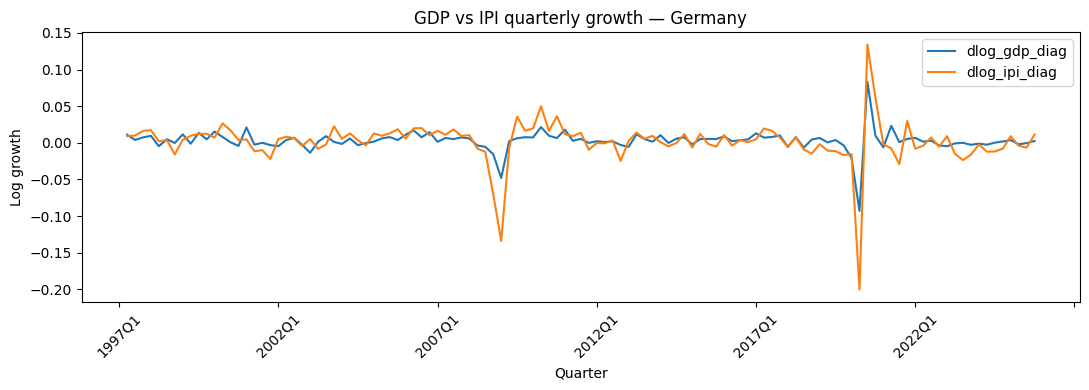

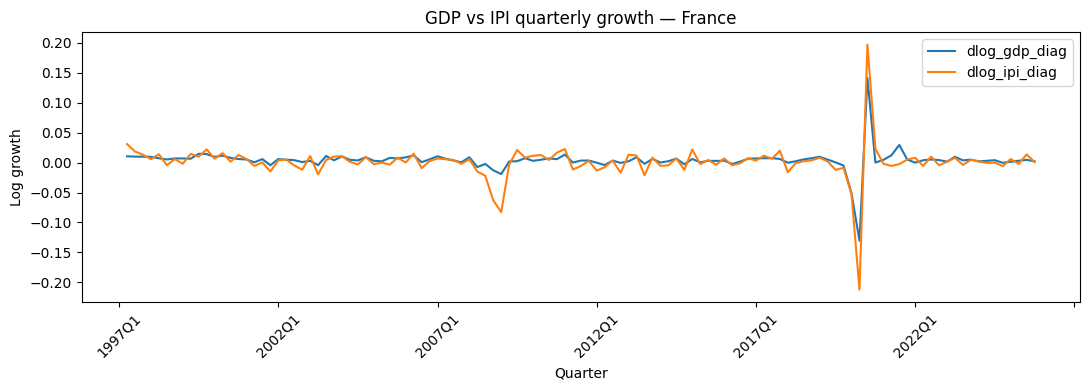

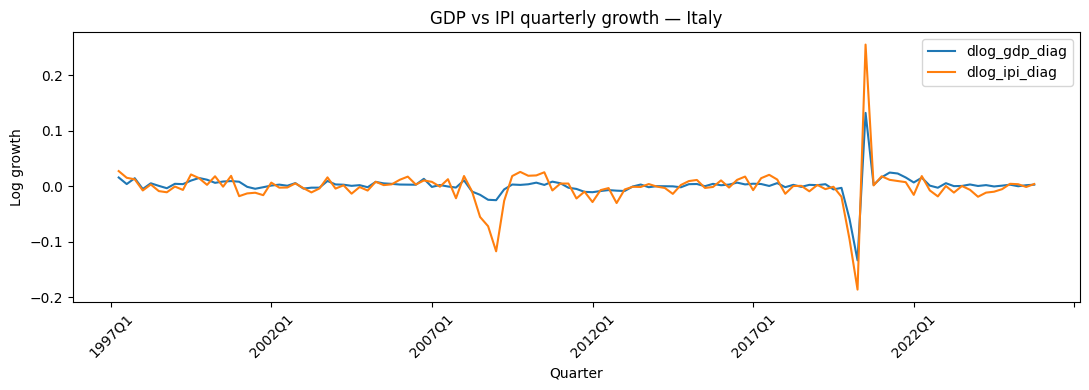

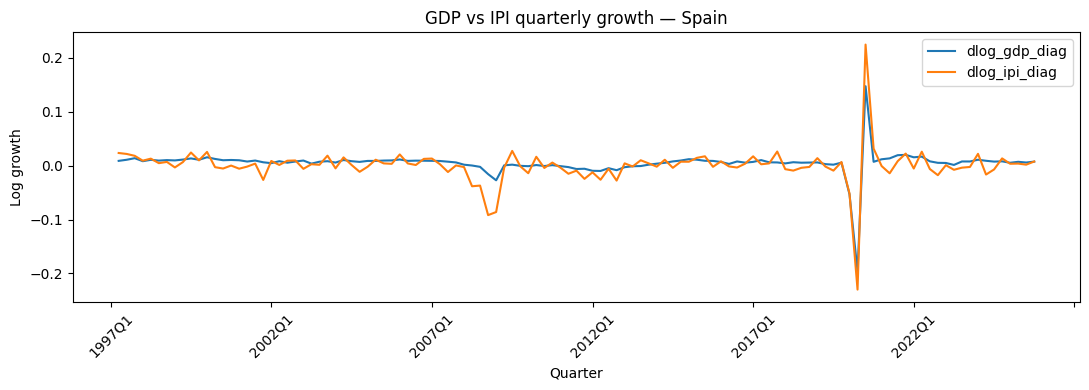

In [22]:
# Visual comparison of quarterly GDP and IPI growth

for country in TARGET_COUNTRIES:
    df = (
        activity[activity["country"] == country]
        .set_index("quarter")[
            ["dlog_gdp_diag", "dlog_ipi_diag"]
        ]
    )

    ax = df.plot(figsize=(11, 4))
    ax.set_title(f"GDP vs IPI quarterly growth — {country}")
    ax.set_xlabel("Quarter")
    ax.set_ylabel("Log growth")
    ax.tick_params(axis="x", labelrotation=45)
    plt.tight_layout()
    plt.show()

The comparison is used to document the baseline choice rather than to eliminate GDP from the project. **IPI remains the baseline activity indicator; GDP is retained as a documented alternative activity measure.**

## Block D — Build the clean quarterly panel

All cleaned quarterly series are merged onto the country-quarter skeleton. The resulting dataset remains in **level form**. Econometric transformations are deferred to the next notebook.

In [23]:
country_quarter = pd.MultiIndex.from_product(
    [skeleton["quarter"], TARGET_COUNTRIES],
    names=["quarter", "country"],
).to_frame(index=False)

panel = country_quarter.copy()

panel = panel.merge(
    gpr,
    on=["quarter", "country"],
    how="left",
)
panel = panel.merge(
    energy_q,
    on="quarter",
    how="left",
)
panel = panel.merge(
    hicp_q,
    on=["quarter", "country"],
    how="left",
)
panel = panel.merge(
    ipi_q,
    on=["quarter", "country"],
    how="left",
)
panel = panel.merge(
    gdp_q,
    on=["quarter", "country"],
    how="left",
)
panel = panel.merge(
    clifs_q,
    on=["quarter", "country"],
    how="left",
)

panel = panel[
    [
        "quarter",
        "country",
        "GPR_Russia",
        "GPR_China",
        "GPR_MENA",
        "GPR_Western",
        "brent_usd",
        "gas_usd",
        "hicp",
        "ipi",
        "gdp",
        "clifs",
    ]
]

print(f"Clean quarterly panel: {panel.shape[0]} rows × {panel.shape[1]} columns")
display(panel.head(12))

Clean quarterly panel: 464 rows × 12 columns


,quarter,country,GPR_Russia,GPR_China,GPR_MENA,GPR_Western,brent_usd,gas_usd,hicp,ipi,gdp,clifs
0,1997Q1,Germany,9.474874,0.000000,38.046743,24.595479,21.170000,2.870000,76.598778,76.066667,77.772,0.085600
1,1997Q1,France,38.417008,55.899691,24.376497,48.921747,21.170000,2.870000,75.680072,95.500000,73.303,0.114067
2,1997Q1,Italy,46.894347,80.050832,33.450371,52.583083,21.170000,2.870000,69.388538,111.933333,91.891,0.082000
3,1997Q1,Spain,47.502121,18.240746,51.703130,58.781181,21.170000,2.870000,65.791649,103.333333,69.662,0.089667
4,1997Q2,Germany,22.084295,33.970353,45.825273,44.950218,18.053333,2.756667,76.703236,76.766667,78.637,0.096167
5,1997Q2,France,30.495020,102.085962,22.933107,37.395292,18.053333,2.756667,75.632409,98.500000,74.073,0.134633
6,1997Q2,Italy,21.644755,37.541362,43.511307,75.364898,18.053333,2.756667,69.614246,115.066667,93.378,0.048000
7,1997Q2,Spain,69.328638,73.210768,33.799768,72.808838,18.053333,2.756667,65.848891,105.800000,70.291,0.062100
8,1997Q3,Germany,16.060424,18.116527,56.571306,52.981891,18.520000,2.680000,77.001855,77.533333,78.946,0.063367
9,1997Q3,France,12.235440,25.919805,28.466808,43.172621,18.520000,2.680000,75.994832,100.333333,74.809,0.134900


## Block E — Validation and export

The final checks document coverage, missing observations and basic descriptive statistics before the clean quarterly panel is saved.

In [24]:
variables = [
    "GPR_Russia",
    "GPR_China",
    "GPR_MENA",
    "GPR_Western",
    "brent_usd",
    "gas_usd",
    "hicp",
    "ipi",
    "gdp",
    "clifs",
]

missing_by_country = (
    panel.groupby("country")[variables]
         .apply(lambda df: df.isna().sum())
)

print("Missing observations by country:")
display(missing_by_country)

Missing observations by country:


,GPR_Russia,GPR_China,GPR_MENA,GPR_Western,brent_usd,gas_usd,hicp,ipi,gdp,clifs
country,,,,,,,,,,
France,0,0,0,0,0,0,0,0,0,0
Germany,0,0,0,0,0,0,0,0,0,0
Italy,0,0,0,0,0,0,0,0,0,0
Spain,0,0,0,0,0,0,0,0,0,0


In [25]:
coverage_rows = []

for country in TARGET_COUNTRIES:
    df = panel[panel["country"] == country]

    for variable in variables:
        available = df.loc[df[variable].notna(), "quarter"]

        coverage_rows.append({
            "country": country,
            "variable": variable,
            "observations": len(available),
            "first_quarter": available.iloc[0] if len(available) else None,
            "last_quarter": available.iloc[-1] if len(available) else None,
        })

coverage = pd.DataFrame(coverage_rows)
display(coverage)

,country,variable,observations,first_quarter,last_quarter
0,Germany,GPR_Russia,116,1997Q1,2025Q4
1,Germany,GPR_China,116,1997Q1,2025Q4
2,Germany,GPR_MENA,116,1997Q1,2025Q4
3,Germany,GPR_Western,116,1997Q1,2025Q4
4,Germany,brent_usd,116,1997Q1,2025Q4
5,Germany,gas_usd,116,1997Q1,2025Q4
6,Germany,hicp,116,1997Q1,2025Q4
7,Germany,ipi,116,1997Q1,2025Q4
8,Germany,gdp,116,1997Q1,2025Q4
9,Germany,clifs,116,1997Q1,2025Q4


In [26]:
for country in TARGET_COUNTRIES:
    print(f"\n{country}")
    display(
        panel.loc[panel["country"] == country, variables]
             .describe()
             .loc[["count", "mean", "std", "min", "max"]]
             .round(2)
    )


Germany


,GPR_Russia,GPR_China,GPR_MENA,GPR_Western,brent_usd,gas_usd,hicp,ipi,gdp,clifs
count,116.00,116.00,116.00,116.00,116.00,116.00,116.00,116.00,116.00,116.00
mean,110.15,111.99,104.33,109.29,61.64,8.60,96.50,94.82,95.20,0.11
std,223.71,155.68,66.93,85.28,30.60,7.73,15.30,8.96,9.64,0.08
min,5.35,0.00,22.52,24.60,11.09,1.82,76.60,76.07,77.77,0.01
max,1643.60,614.42,415.24,430.94,122.39,60.16,133.02,109.77,109.04,0.46



France


,GPR_Russia,GPR_China,GPR_MENA,GPR_Western,brent_usd,gas_usd,hicp,ipi,gdp,clifs
count,116.00,116.00,116.00,116.00,116.00,116.00,116.00,116.00,116.00,116.00
mean,124.77,116.40,104.70,100.58,61.64,8.60,95.80,105.25,95.66,0.12
std,225.24,100.21,81.08,61.67,30.60,7.73,13.74,5.60,10.30,0.08
min,10.70,5.72,14.47,35.19,11.09,1.82,75.63,80.77,73.30,0.03
max,1735.96,449.16,537.99,300.22,122.39,60.16,124.81,116.00,113.44,0.44



Italy


,GPR_Russia,GPR_China,GPR_MENA,GPR_Western,brent_usd,gas_usd,hicp,ipi,gdp,clifs
count,116.00,116.00,116.00,116.00,116.00,116.00,116.00,116.00,116.00,116.00
mean,107.20,110.69,103.44,106.06,61.64,8.60,93.93,106.07,102.99,0.09
std,202.10,135.20,66.74,63.68,30.60,7.73,15.13,11.01,4.67,0.08
min,6.98,0.00,23.73,26.12,11.09,1.82,69.39,74.47,85.68,0.02
max,1508.10,661.73,384.91,303.68,122.39,60.16,124.62,124.43,111.22,0.45



Spain


,GPR_Russia,GPR_China,GPR_MENA,GPR_Western,brent_usd,gas_usd,hicp,ipi,gdp,clifs
count,116.00,116.00,116.00,116.00,116.00,116.00,116.00,116.00,116.00,116.00
mean,104.33,106.07,103.03,104.08,61.64,8.60,93.86,107.98,97.82,0.11
std,200.38,100.44,70.89,54.68,30.60,7.73,16.53,11.67,12.50,0.08
min,6.60,4.53,32.47,43.15,11.09,1.82,65.79,77.47,69.66,0.02
max,1589.08,485.67,514.61,433.39,122.39,60.16,128.20,131.77,123.06,0.47


In [27]:
# Final structural checks

assert panel[["quarter", "country"]].duplicated().sum() == 0
assert panel["country"].nunique() == len(TARGET_COUNTRIES)
assert panel["quarter"].min() == skeleton["quarter"].min()
assert panel["quarter"].max() == skeleton["quarter"].max()

print("Final structural checks passed.")
print(f"Panel range: {panel['quarter'].min()} – {panel['quarter'].max()}")
print(f"Countries: {sorted(panel['country'].unique())}")

Final structural checks passed.
Panel range: 1997Q1 – 2025Q4
Countries: ['France', 'Germany', 'Italy', 'Spain']


In [28]:
# Export the clean quarterly panel.
# This is the level-data input for the next notebook.

CLEAN_QUARTERLY_PANEL_PATH = (
    PROCESSED_DATA_DIR / "03_clean_quarterly_panel.xlsx"
)

panel.to_excel(CLEAN_QUARTERLY_PANEL_PATH, index=False)

print(f"Saved to: {CLEAN_QUARTERLY_PANEL_PATH}")
print(f"Shape: {panel.shape[0]} rows × {panel.shape[1]} columns")

Saved to: /content/drive/MyDrive/TFM_GitHub/data/processed/03_clean_quarterly_panel.xlsx
Shape: 464 rows × 12 columns
